In [14]:


import pandas as pd
from pathlib import Path

# Chemin vers le dataset
chemin = Path("../data/2019-Oct.csv")

# Vérifier si le fichier existe
print("Fichier trouvé :", chemin.exists())

# Charger les 100 000 premières lignes
if chemin.exists():
    df = pd.read_csv(chemin, nrows=100000)
    print("Dataset chargé avec succès !")
    display(df.head())
else:
    print("Le fichier CSV est introuvable.")




Fichier trouvé : True
Dataset chargé avec succès !


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00 UTC,cart,5773203,1487580005134238553,NaN,runail,2.62,463240011,26dd6e6e-4dac-4778-8d2c-92e149dab885
1,2019-10-01 00:00:03 UTC,cart,5773353,1487580005134238553,NaN,runail,2.62,463240011,26dd6e6e-4dac-4778-8d2c-92e149dab885
2,2019-10-01 00:00:07 UTC,cart,5881589,2151191071051219817,NaN,lovely,13.48,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9
3,2019-10-01 00:00:07 UTC,cart,5723490,1487580005134238553,NaN,runail,2.62,463240011,26dd6e6e-4dac-4778-8d2c-92e149dab885
4,2019-10-01 00:00:15 UTC,cart,5881449,1487580013522845895,NaN,lovely,0.56,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9


In [15]:

# Dimensions du dataset
print("Dimensions :", df.shape)

# Informations générales
print("\nInformations sur les colonnes :")
df.info()

# Statistiques descriptives
display(df.describe())



Dimensions : (100000, 9)

Informations sur les colonnes :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   event_time     100000 non-null  object 
 1   event_type     100000 non-null  object 
 2   product_id     100000 non-null  int64  
 3   category_id    100000 non-null  int64  
 4   category_code  1808 non-null    object 
 5   brand          60062 non-null   object 
 6   price          100000 non-null  float64
 7   user_id        100000 non-null  int64  
 8   user_session   99994 non-null   object 
dtypes: float64(1), int64(3), object(5)
memory usage: 6.9+ MB


,product_id,category_id,price,user_id
count,1.000000e+05,1.000000e+05,100000.00000,1.000000e+05
mean,5.469531e+06,1.544130e+18,8.79847,4.977820e+08
std,1.315268e+06,1.564729e+17,19.70357,7.919352e+07
min,3.752000e+03,1.487580e+18,0.00000,9.794320e+06
25%,5.723488e+06,1.487580e+18,2.06000,4.676014e+08
50%,5.804394e+06,1.487580e+18,3.97000,5.343075e+08
75%,5.847526e+06,1.487580e+18,7.33000,5.549492e+08
max,5.892349e+06,2.195085e+18,299.81000,5.557384e+08


In [16]:

# Nombre de valeurs manquantes
missing_values = df.isnull().sum()

# Pourcentage de valeurs manquantes
missing_percent = df.isnull().mean() * 100

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": missing_percent.round(2)
})

display(missing_report)


,Missing Values,Missing Percentage (%)
event_time,0,0.00
event_type,0,0.00
product_id,0,0.00
category_id,0,0.00
category_code,98192,98.19
brand,39938,39.94
price,0,0.00
user_id,0,0.00
user_session,6,0.01


Répartition des événements :


event_type
view                43657
cart                29587
remove_from_cart    19912
purchase             6844
Name: count, dtype: int64

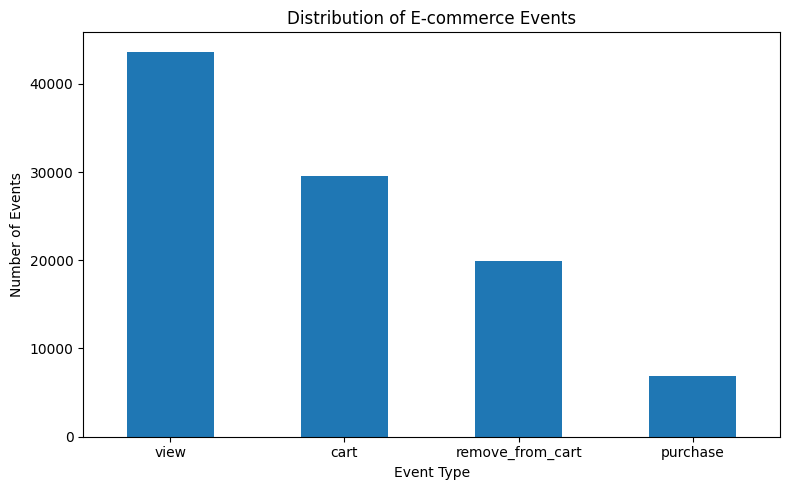

In [17]:

# Compter les événements
event_counts = df["event_type"].value_counts()

print("Répartition des événements :")
display(event_counts)

# Visualisation
plt.figure(figsize=(8, 5))

event_counts.plot(kind="bar")

plt.title("Distribution of E-commerce Events")
plt.xlabel("Event Type")
plt.ylabel("Number of Events")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [18]:

# Créer une copie pour conserver les données originales
df_clean = df.copy()

print("Dimensions initiales :", df_clean.shape)


Dimensions initiales : (100000, 9)


In [19]:

# Remplacer les marques manquantes
df_clean["brand"] = df_clean["brand"].fillna("Unknown")

# Remplacer les catégories textuelles manquantes
df_clean["category_code"] = df_clean["category_code"].fillna("Unknown")

# Vérifier les sessions manquantes
print("Sessions manquantes :")
print(df_clean["user_session"].isna().sum())


Sessions manquantes :
6


In [20]:

# Conversion en datetime
df_clean["event_time"] = pd.to_datetime(
    df_clean["event_time"],
    utc=True,
    errors="coerce"
)

# Créer des colonnes temporelles
df_clean["date"] = df_clean["event_time"].dt.date
df_clean["hour"] = df_clean["event_time"].dt.hour

display(df_clean[["event_time", "date", "hour"]].head())


,event_time,date,hour
0,2019-10-01 00:00:00+00:00,2019-10-01,0
1,2019-10-01 00:00:03+00:00,2019-10-01,0
2,2019-10-01 00:00:07+00:00,2019-10-01,0
3,2019-10-01 00:00:07+00:00,2019-10-01,0
4,2019-10-01 00:00:15+00:00,2019-10-01,0


In [21]:

# Nombre de lignes identiques
duplicates = df_clean.duplicated().sum()

print("Doublons exacts :", duplicates)

# Vérifier les prix
print("Prix négatifs :", (df_clean["price"] < 0).sum())
print("Prix égaux à zéro :", (df_clean["price"] == 0).sum())

# Statistiques des prix
display(df_clean["price"].describe())


Doublons exacts : 5488
Prix négatifs : 0
Prix égaux à zéro : 129


count    100000.00000
mean          8.79847
std          19.70357
min           0.00000
25%           2.06000
50%           3.97000
75%           7.33000
max         299.81000
Name: price, dtype: float64

In [22]:

# Identifier les doublons sur les 9 colonnes originales
colonnes_originales = df.columns.tolist()

doublons = df_clean[
    df_clean.duplicated(
        subset=colonnes_originales,
        keep=False
    )
].sort_values("event_time")

print("Lignes appartenant à des groupes de doublons :")
display(doublons.head(10))

# Répartition des doublons supplémentaires par type
doublons_supp = df_clean[
    df_clean.duplicated(
        subset=colonnes_originales
    )
]

print("\nDoublons supplémentaires par événement :")
print(doublons_supp["event_type"].value_counts())


Lignes appartenant à des groupes de doublons :


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,date,hour
12,2019-10-01 00:00:30+00:00,remove_from_cart,5809103,1487580013522845895,Unknown,irisk,0.60,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9,2019-10-01,0
13,2019-10-01 00:00:30+00:00,remove_from_cart,5809103,1487580013522845895,Unknown,irisk,0.60,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9,2019-10-01,0
29,2019-10-01 00:01:05+00:00,remove_from_cart,5858981,1487580007634043851,Unknown,de.lux,0.79,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9,2019-10-01,0
30,2019-10-01 00:01:05+00:00,remove_from_cart,5858981,1487580007634043851,Unknown,de.lux,0.79,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9,2019-10-01,0
34,2019-10-01 00:01:07+00:00,remove_from_cart,5312,1487580009471148064,Unknown,runail,1.27,467916806,2f5b5546-b8cb-9ee7-7ecd-84276f8ef486,2019-10-01,0
36,2019-10-01 00:01:07+00:00,remove_from_cart,5312,1487580009471148064,Unknown,runail,1.27,467916806,2f5b5546-b8cb-9ee7-7ecd-84276f8ef486,2019-10-01,0
37,2019-10-01 00:01:10+00:00,remove_from_cart,5823915,1487580007432717250,Unknown,milv,1.59,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9,2019-10-01,0
38,2019-10-01 00:01:10+00:00,remove_from_cart,5823915,1487580007432717250,Unknown,milv,1.59,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9,2019-10-01,0
51,2019-10-01 00:01:24+00:00,remove_from_cart,5664641,1487580011425693811,Unknown,Unknown,0.70,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9,2019-10-01,0
50,2019-10-01 00:01:24+00:00,remove_from_cart,5664641,1487580011425693811,Unknown,Unknown,0.70,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9,2019-10-01,0



Doublons supplémentaires par événement :
event_type
remove_from_cart    4940
cart                 538
purchase               7
view                   3
Name: count, dtype: int64


In [23]:

# Sélectionner les événements avec un prix nul
zero_price = df_clean[df_clean["price"] == 0]

print("Événements avec prix zéro :", len(zero_price))

print("\nTypes d'événements concernés :")
print(zero_price["event_type"].value_counts())

print("\nExemples :")
display(zero_price.head(10))


Événements avec prix zéro : 129

Types d'événements concernés :
event_type
view                114
cart                 13
remove_from_cart      2
Name: count, dtype: int64

Exemples :


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,date,hour
2454,2019-10-01 02:05:17+00:00,view,5892084,1597770225539875791,Unknown,Unknown,0.0,555458569,c048be2f-547d-4add-9bc6-09aa1e7ae9de,2019-10-01,2
2614,2019-10-01 02:15:41+00:00,view,5892052,1487580010377117763,Unknown,Unknown,0.0,555455025,320f6021-30ac-4a58-ae17-bac1cc32aac3,2019-10-01,2
5686,2019-10-01 04:25:00+00:00,view,5873432,2007399943458784057,apparel.glove,Unknown,0.0,500054739,701220b4-45b4-4028-bcc3-5d77480253ff,2019-10-01,4
6086,2019-10-01 04:33:15+00:00,view,5882605,1487580013522845895,Unknown,Unknown,0.0,523154930,caaf1f68-7b97-4d27-9c3d-8b28c2920ffd,2019-10-01,4
8344,2019-10-01 05:16:30+00:00,view,5889621,1487580010561667147,Unknown,Unknown,0.0,523988665,00849bd2-fcd2-4cb4-af31-4e264f151848,2019-10-01,5
8417,2019-10-01 05:18:03+00:00,view,5889622,1487580010561667147,Unknown,Unknown,0.0,523988665,80cfe614-f0a5-4101-a2b6-a21227590470,2019-10-01,5
8465,2019-10-01 05:18:46+00:00,view,5889623,1487580010561667147,Unknown,Unknown,0.0,523988665,c2cd0464-3d2b-48e2-9667-bac248fe297a,2019-10-01,5
8950,2019-10-01 05:24:38+00:00,view,5873431,2007399943458784057,apparel.glove,Unknown,0.0,542778344,7c4f6972-ead8-46f1-85d4-e7d7028f06c3,2019-10-01,5
10125,2019-10-01 05:38:01+00:00,view,5889627,1487580010561667147,Unknown,Unknown,0.0,523988665,8b2bf9d8-43f0-43b2-bed3-13b2c956cada,2019-10-01,5
10154,2019-10-01 05:38:32+00:00,view,5889628,1487580010561667147,Unknown,Unknown,0.0,523988665,b7087089-41f5-48bc-b7eb-52fea86fa22c,2019-10-01,5


In [24]:

print("Première date :", df_clean["event_time"].min())
print("Dernière date :", df_clean["event_time"].max())

print("\nNombre de jours distincts :")
print(df_clean["date"].nunique())


Première date : 2019-10-01 00:00:00+00:00
Dernière date : 2019-10-01 17:57:23+00:00

Nombre de jours distincts :
1


In [25]:

import pandas as pd
from pathlib import Path

chemin = Path("../data/2019-Oct.csv")

echantillons = []

# Lecture progressive du fichier
for chunk in pd.read_csv(chemin, chunksize=100000):

    # Sélection aléatoire de 10 % des lignes
    sample = chunk.sample(frac=0.10, random_state=42)

    echantillons.append(sample)

# Regrouper les échantillons
df_month = pd.concat(echantillons, ignore_index=True)

print("Échantillon créé !")
print("Dimensions :", df_month.shape)


Échantillon créé !
Dimensions : (410228, 9)


In [26]:

# Convertir les dates
df_month["event_time"] = pd.to_datetime(
    df_month["event_time"],
    utc=True
)

# Vérifier la période
print("Première date :", df_month["event_time"].min())
print("Dernière date :", df_month["event_time"].max())

# Nombre de jours
print(
    "Nombre de jours :",
    df_month["event_time"].dt.date.nunique()
)


Première date : 2019-10-01 00:00:56+00:00
Dernière date : 2019-10-31 23:59:06+00:00
Nombre de jours : 31


In [27]:

print("Répartition des événements :")
display(df_month["event_type"].value_counts())

print("\nValeurs manquantes :")
display(df_month.isnull().sum())


Répartition des événements :


event_type
view                185867
cart                123395
remove_from_cart     76320
purchase             24646
Name: count, dtype: int64


Valeurs manquantes :


event_time            0
event_type            0
product_id            0
category_id           0
category_code    403279
brand            166039
price                 0
user_id               0
user_session         64
dtype: int64

In [28]:

# Copier l'échantillon
df_month_clean = df_month.copy()

# Remplacer les informations textuelles manquantes
df_month_clean["brand"] = (
    df_month_clean["brand"].fillna("Unknown")
)

df_month_clean["category_code"] = (
    df_month_clean["category_code"].fillna("Unknown")
)

# Créer les colonnes temporelles
df_month_clean["date"] = (
    df_month_clean["event_time"].dt.date
)

df_month_clean["hour"] = (
    df_month_clean["event_time"].dt.hour
)

# Vérifier le résultat
print("Dimensions :", df_month_clean.shape)
display(df_month_clean.head())


Dimensions : (410228, 11)


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,date,hour
0,2019-10-01 14:30:03+00:00,cart,5723518,1487580005134238553,Unknown,runail,2.62,547935272,0a308fb1-380b-4f9f-a619-4dcfff68bf20,2019-10-01,14
1,2019-10-01 15:10:35+00:00,remove_from_cart,5788525,1487580005671109489,Unknown,masura,3.95,545177712,ad3e231a-c892-49cd-9ddb-0b83d5c1c0b3,2019-10-01,15
2,2019-10-01 07:09:39+00:00,remove_from_cart,5875394,2084144451428549153,Unknown,Unknown,2.05,552286984,2e6c5b45-ce74-491c-b198-513cf3e4c1fe,2019-10-01,7
3,2019-10-01 14:39:13+00:00,view,5677402,1487580008263189483,Unknown,estel,7.78,358204750,a73a4523-1f4c-9ec0-3ce5-326d2b23674f,2019-10-01,14
4,2019-10-01 17:15:42+00:00,cart,5621591,1487580007306888126,Unknown,Unknown,6.83,555719501,7e2af7cc-4a9e-48b1-ae88-21ed6573cc7e,2019-10-01,17


In [29]:

from pathlib import Path

output_path = Path("../data/ecommerce_sample_clean.csv")

df_month_clean.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Fichier enregistré :", output_path.resolve())


Fichier enregistré : C:\Users\ASUS\Desktop\Ecommerce_Performance_Analysis\Data\ecommerce_sample_clean.csv


In [30]:

import pandas as pd
from pathlib import Path

chemin = Path("../data/2019-Oct.csv")

session_parts = []

for chunk in pd.read_csv(
    chemin,
    chunksize=100000,
    usecols=["user_session", "event_type"]
):
    # Exclure les événements sans session
    chunk = chunk.dropna(subset=["user_session"])

    # Agréger chaque morceau par session
    summary = pd.crosstab(
        chunk["user_session"],
        chunk["event_type"]
    )

    session_parts.append(summary)

# Regrouper les résultats des différents morceaux
session_events = pd.concat(session_parts)

# Fusionner les sessions répétées entre morceaux
session_events = session_events.groupby(level=0).sum()

# Garantir la présence des colonnes nécessaires
for col in ["view", "cart", "remove_from_cart", "purchase"]:
    if col not in session_events.columns:
        session_events[col] = 0

# Transformer les nombres en indicateurs
session_kpi = pd.DataFrame({
    "user_session": session_events.index,
    "has_view": (session_events["view"] > 0).astype(int),
    "has_cart": (session_events["cart"] > 0).astype(int),
    "has_purchase": (session_events["purchase"] > 0).astype(int)
}).reset_index(drop=True)

# Enregistrer pour Power BI
session_kpi.to_csv(
    "../data/session_kpi.csv",
    index=False
)

print("Nombre de sessions :", len(session_kpi))
print("Sessions avec achat :", session_kpi["has_purchase"].sum())


Nombre de sessions : 873960
Sessions avec achat : 29326


In [31]:

total_sessions = len(session_kpi)

purchase_sessions = session_kpi["has_purchase"].sum()

conversion_rate = (
    purchase_sessions / total_sessions * 100
)

print(f"Sessions totales : {total_sessions:,}")
print(f"Sessions avec achat : {purchase_sessions:,}")
print(f"Taux de conversion : {conversion_rate:.2f}%")


Sessions totales : 873,960
Sessions avec achat : 29,326
Taux de conversion : 3.36%


In [32]:

# Nombre de sessions par événement
total_sessions = len(session_kpi)

view_sessions = session_kpi["has_view"].sum()
cart_sessions = session_kpi["has_cart"].sum()
purchase_sessions = session_kpi["has_purchase"].sum()

print("Total sessions :", total_sessions)
print("Sessions avec vue :", view_sessions)
print("Sessions avec panier :", cart_sessions)
print("Sessions avec achat :", purchase_sessions)


Total sessions : 873960
Sessions avec vue : 826147
Sessions avec panier : 228145
Sessions avec achat : 29326


In [33]:

# Taux de passage entre les étapes
view_rate = view_sessions / total_sessions * 100

cart_rate = (
    cart_sessions / view_sessions * 100
    if view_sessions > 0 else 0
)

purchase_rate = (
    purchase_sessions / cart_sessions * 100
    if cart_sessions > 0 else 0
)

print(f"Sessions avec vue : {view_rate:.2f}%")
print(f"Panier / Vue : {cart_rate:.2f}%")
print(f"Achat / Panier : {purchase_rate:.2f}%")


Sessions avec vue : 94.53%
Panier / Vue : 27.62%
Achat / Panier : 12.85%


In [34]:

# Nombre de sessions par événement
total_sessions = len(session_kpi)

view_sessions = session_kpi["has_view"].sum()
cart_sessions = session_kpi["has_cart"].sum()
purchase_sessions = session_kpi["has_purchase"].sum()

print("Total sessions :", total_sessions)
print("Sessions avec vue :", view_sessions)
print("Sessions avec panier :", cart_sessions)
print("Sessions avec achat :", purchase_sessions)


Total sessions : 873960
Sessions avec vue : 826147
Sessions avec panier : 228145
Sessions avec achat : 29326


In [35]:

# Taux de passage entre les étapes
view_rate = view_sessions / total_sessions * 100

cart_rate = (
    cart_sessions / view_sessions * 100
    if view_sessions > 0 else 0
)

purchase_rate = (
    purchase_sessions / cart_sessions * 100
    if cart_sessions > 0 else 0
)

print(f"Sessions avec vue : {view_rate:.2f}%")
print(f"Panier / Vue : {cart_rate:.2f}%")
print(f"Achat / Panier : {purchase_rate:.2f}%")


Sessions avec vue : 94.53%
Panier / Vue : 27.62%
Achat / Panier : 12.85%


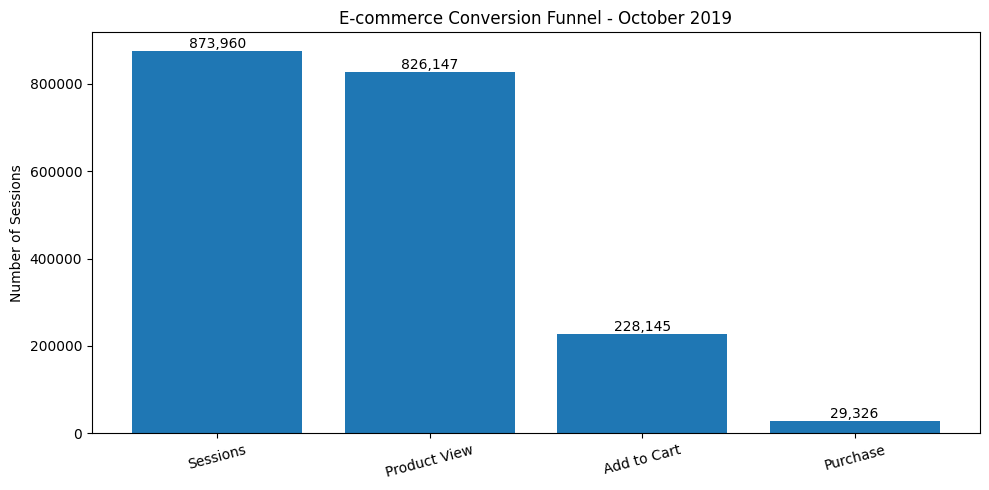

In [36]:

import matplotlib.pyplot as plt

steps = ["Sessions", "Product View", "Add to Cart", "Purchase"]

values = [
    total_sessions,
    view_sessions,
    cart_sessions,
    purchase_sessions
]

plt.figure(figsize=(10, 5))
plt.bar(steps, values)

plt.title("E-commerce Conversion Funnel - October 2019")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=15)

for i, value in enumerate(values):
    plt.text(i, value, f"{value:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()


In [37]:

import pandas as pd

chemin = "../data/2019-Oct.csv"

total_revenue = 0
purchase_events = 0
purchase_sessions = set()

for chunk in pd.read_csv(
    chemin,
    chunksize=100000,
    usecols=["event_type", "price", "user_session"]
):
    # Garder uniquement les achats
    purchases = chunk[
        chunk["event_type"] == "purchase"
    ]

    # Additionner les prix des achats
    total_revenue += purchases["price"].sum()

    # Compter les événements d'achat
    purchase_events += len(purchases)

    # Collecter les sessions avec achat
    purchase_sessions.update(
        purchases["user_session"].dropna().unique()
    )

print(f"Montant total des achats : {total_revenue:,.2f}")
print(f"Événements d'achat : {purchase_events:,}")
print(f"Sessions avec achat : {len(purchase_sessions):,}")


Montant total des achats : 1,211,538.43
Événements d'achat : 245,624
Sessions avec achat : 29,326


In [38]:

average_purchase_value = (
    total_revenue / purchase_events
    if purchase_events > 0 else 0
)

print(
    f"Valeur moyenne par événement d'achat : "
    f"{average_purchase_value:.2f}"
)


Valeur moyenne par événement d'achat : 4.93


In [39]:

from collections import defaultdict

daily_revenue = defaultdict(float)

for chunk in pd.read_csv(
    chemin,
    chunksize=100000,
    usecols=["event_time", "event_type", "price"]
):
    purchases = chunk[
        chunk["event_type"] == "purchase"
    ].copy()

    purchases["date"] = pd.to_datetime(
        purchases["event_time"],
        utc=True
    ).dt.date

    daily = purchases.groupby("date")["price"].sum()

    for date, revenue in daily.items():
        daily_revenue[date] += revenue

daily_sales = pd.DataFrame(
    sorted(daily_revenue.items()),
    columns=["date", "revenue"]
)

display(daily_sales.head())


,date,revenue
0,2019-10-01,43497.17
1,2019-10-02,45746.20
2,2019-10-03,43380.98
3,2019-10-04,35887.15
4,2019-10-05,29228.55


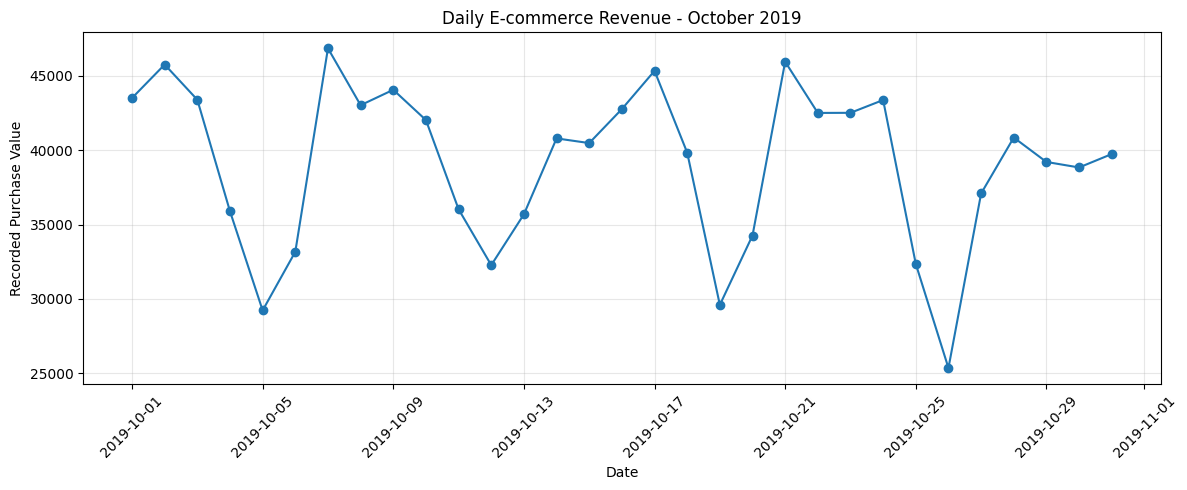

In [40]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    daily_sales["date"],
    daily_sales["revenue"],
    marker="o"
)

plt.title("Daily E-commerce Revenue - October 2019")
plt.xlabel("Date")
plt.ylabel("Recorded Purchase Value")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [41]:

import pandas as pd

chemin = "../data/2019-Oct.csv"

product_parts = []

for chunk in pd.read_csv(
    chemin,
    chunksize=100000,
    usecols=["event_type", "product_id", "price"]
):
    purchases = chunk[
        chunk["event_type"] == "purchase"
    ]

    summary = purchases.groupby("product_id").agg(
        purchase_events=("price", "size"),
        revenue=("price", "sum")
    )

    product_parts.append(summary)

# Regrouper les résultats de tous les morceaux
product_sales = pd.concat(product_parts)

product_sales = (
    product_sales.groupby(level=0)
    .sum()
    .reset_index()
)

# Trier par montant des achats
product_sales = product_sales.sort_values(
    "revenue",
    ascending=False
)

print("Top 10 des produits :")
display(product_sales.head(10))


Top 10 des produits :


,product_id,purchase_events,revenue
23355,5877454,251,11116.79
1308,5560754,44,8555.36
1309,5560756,37,7693.78
19450,5856186,94,7087.60
6885,5751422,644,7051.80
17721,5846437,139,6288.36
9869,5792800,592,6109.44
6849,5751383,566,5841.12
19413,5855507,73,5782.33
18217,5849033,440,4540.80


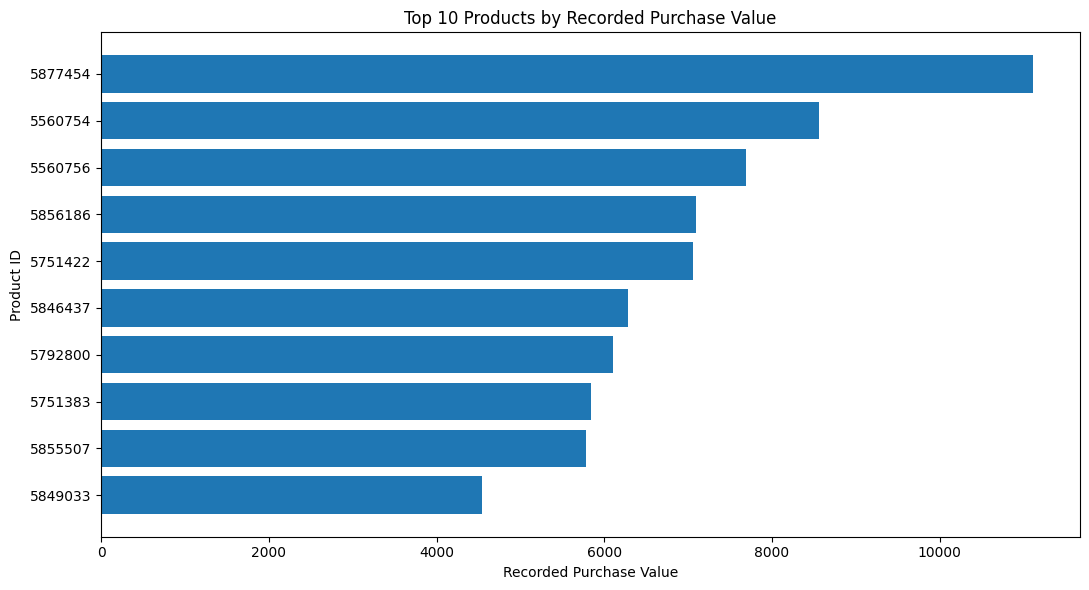

In [42]:

import matplotlib.pyplot as plt

top_products = product_sales.head(10).copy()

plt.figure(figsize=(11, 6))

plt.barh(
    top_products["product_id"].astype(str),
    top_products["revenue"]
)

plt.title("Top 10 Products by Recorded Purchase Value")
plt.xlabel("Recorded Purchase Value")
plt.ylabel("Product ID")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [43]:

brand_parts = []

for chunk in pd.read_csv(
    chemin,
    chunksize=100000,
    usecols=["event_type", "brand", "price"]
):
    purchases = chunk[
        chunk["event_type"] == "purchase"
    ].copy()

    purchases["brand"] = (
        purchases["brand"].fillna("Unknown")
    )

    summary = purchases.groupby("brand").agg(
        purchase_events=("price", "size"),
        revenue=("price", "sum")
    )

    brand_parts.append(summary)

brand_sales = pd.concat(brand_parts)

brand_sales = (
    brand_sales.groupby(level=0)
    .sum()
    .reset_index()
    .sort_values("revenue", ascending=False)
)

print("Top 10 des marques :")
display(brand_sales.head(10))


Top 10 des marques :


,brand,purchase_events,revenue
0,Unknown,100697,474679.06
172,runail,21936,71539.28
89,irisk,15645,45591.96
79,grattol,6438,35445.54
200,uno,3218,35302.03
133,masura,11356,31266.08
29,cnd,2305,30074.18
188,strong,158,29196.63
93,jessnail,1803,26287.84
85,ingarden,5181,23161.39


In [44]:

product_sales.to_csv(
    "../data/product_sales.csv",
    index=False
)

brand_sales.to_csv(
    "../data/brand_sales.csv",
    index=False
)

daily_sales.to_csv(
    "../data/daily_sales.csv",
    index=False
)

print("Les trois fichiers ont été enregistrés !")


Les trois fichiers ont été enregistrés !


In [ ]:

# Montant total des achats
total_product_revenue = product_sales["revenue"].sum()

# Montant des 10 premiers produits
top10_revenue = product_sales.head(10)["revenue"].sum()

# Contribution des 10 premiers produits
top10_share = top10_revenue / total_product_revenue * 100

print(f"Montant total : {total_product_revenue:,.2f}")
print(f"Top 10 produits : {top10_revenue:,.2f}")
print(f"Contribution du Top 10 : {top10_share:.2f}%")


In [ ]:

import matplotlib.pyplot as plt

# Exclure les marques inconnues du classement
known_brands = brand_sales[
    brand_sales["brand"] != "Unknown"
]

top10_brands = known_brands.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top10_brands["brand"],
    top10_brands["revenue"]
)

plt.title("Top 10 Known Brands by Purchase Value")
plt.xlabel("Recorded Purchase Value")
plt.ylabel("Brand")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
